# EfficientNetB0 — Member 2

**Student:** Hettiarachchi H.A.A.S  
**IT Number:** IT25104064  
**Dataset:** `maleeshaweerakkody/brain-tumor-mri-preprocessed`  
**Training type:** ImageNet pretrained weights (transfer learning)

This notebook contains **20 numbered topics** and is designed for the Final Evaluation implementation.


## 1. Project, Member and Model Overview

**Problem:** four-class Brain Tumor MRI classification.

**Classes:** glioma, meningioma, no-tumor and pituitary (the exact folder names are detected automatically).

**Assigned model:** **EfficientNetB0**

**Final selection rule:** choose the best tuned variety using **Validation Macro F1**, then evaluate that selected variety on the untouched Official Test set.

**Additional validation:** after selecting the better A/B configuration, perform **5-fold stratified cross-validation** using Training data only to measure stability and generalization.


## 2. Model Suitability and Final Evaluation Requirements

### Final Evaluation coverage

This notebook is organized around the implementation-viva requirements:

- **Student:** Hettiarachchi H.A.A.S — IT25104064
- **Member:** 2
- **Assigned model:** EfficientNetB0
- **Method:** ImageNet transfer learning followed by fine-tuning
- **Model suitability:** EfficientNetB0 is suitable because it provides a strong balance between model efficiency and visual feature-learning capability. ImageNet transfer learning is useful for this relatively small MRI dataset.
- **Implementation details:** TensorFlow/Keras, EfficientNetB0 model builder, model-specific preprocessing, augmentation, optimizer, learning rate, dropout, callbacks and fine-tuning are shown in code.
- **Manual parameter tuning:** Variant A and Variant B use different classifier, dropout, learning-rate and fine-tuning settings.
- **Variety comparison:** both varieties are evaluated using Validation Accuracy, Macro Precision, Macro Recall and Macro F1.
- **Validation method:** a stratified hold-out Validation set is used for A/B selection; the selected configuration is then checked with 5-fold stratified cross-validation. The Official Test set remains separate and is used only for final evaluation.
- **Conclusion:** the variety with the highest Validation Macro F1 is selected; 5-fold CV is reported as additional generalization evidence.
- **Limitations/improvements:** included in Topic 20.


## 3. Install Required Libraries

In [ ]:
%pip -q install kagglehub scikit-learn

## 4. Import Libraries and Set Reproducibility

In [ ]:
from pathlib import Path
import json
import shutil
import zipfile
import random
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import kagglehub

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

KAGGLE_DATASET = "maleeshaweerakkody/brain-tumor-mri-preprocessed"

IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# Model ownership

MODEL_OWNER = "Hettiarachchi H.A.A.S"
OWNER_IT_NUMBER = "IT25104064"
OWNER_MEMBER_NO = 2

print("Model Owner:", MODEL_OWNER)
print("IT Number:", OWNER_IT_NUMBER)
print("Assigned Model:", "EfficientNetB0")


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Model Owner: Hettiarachchi H.A.A.S
IT Number: IT25104064
Assigned Model: EfficientNetB0


## 5. Download Final Preprocessed Kaggle Dataset

In [ ]:
KAGGLE_ROOT = Path(
    kagglehub.dataset_download(
        KAGGLE_DATASET
    )
)

WORK_DIR = Path(
    "/content/brain_tumor_high_performance"
)

DATA_ROOT = WORK_DIR / "dataset"
MODEL_DIR = WORK_DIR / "models"
RESULTS_DIR = WORK_DIR / "results"

for p in [
    DATA_ROOT,
    MODEL_DIR,
    RESULTS_DIR
]:
    p.mkdir(
        parents=True,
        exist_ok=True
    )

zip_files = list(
    KAGGLE_ROOT.rglob("*.zip")
)

if zip_files:
    for zpath in zip_files:
        with zipfile.ZipFile(
            zpath,
            "r"
        ) as zf:
            zf.extractall(
                DATA_ROOT
            )

    SEARCH_ROOT = DATA_ROOT
else:
    SEARCH_ROOT = KAGGLE_ROOT

print("Dataset root:", SEARCH_ROOT)

Using Colab cache for faster access to the 'brain-tumor-mri-preprocessed' dataset.
Dataset root: /kaggle/input/brain-tumor-mri-preprocessed


## 6. Detect Training, Validation and Official Test Folders

In [ ]:
def find_split_dir(
    root,
    names
):
    names = {
        x.lower()
        for x in names
    }

    matches = [
        p
        for p in root.rglob("*")
        if p.is_dir()
        and p.name.lower() in names
    ]

    if not matches:
        return None

    return sorted(
        matches,
        key=lambda p: (
            -len([
                x
                for x in p.iterdir()
                if x.is_dir()
            ]),
            len(p.parts)
        )
    )[0]


TRAIN_DIR = find_split_dir(
    SEARCH_ROOT,
    ["train", "training"]
)

VAL_DIR = find_split_dir(
    SEARCH_ROOT,
    ["validation", "valid", "val"]
)

TEST_DIR = find_split_dir(
    SEARCH_ROOT,
    ["test", "testing"]
)

print("Training:", TRAIN_DIR)
print("Validation:", VAL_DIR)
print("Official Test:", TEST_DIR)

assert TRAIN_DIR is not None
assert VAL_DIR is not None
assert TEST_DIR is not None

Training: /kaggle/input/brain-tumor-mri-preprocessed/train
Validation: /kaggle/input/brain-tumor-mri-preprocessed/validation
Official Test: /kaggle/input/brain-tumor-mri-preprocessed/test


## 7. EDA and Class Distribution

Exact class order:
0 -> glioma_tumor
1 -> meningioma_tumor
2 -> no_tumor
3 -> pituitary_tumor


,Class,Training,Validation,Official Test
0,glioma_tumor,654,164,100
1,meningioma_tumor,654,163,115
2,no_tumor,654,54,105
3,pituitary_tumor,654,162,74


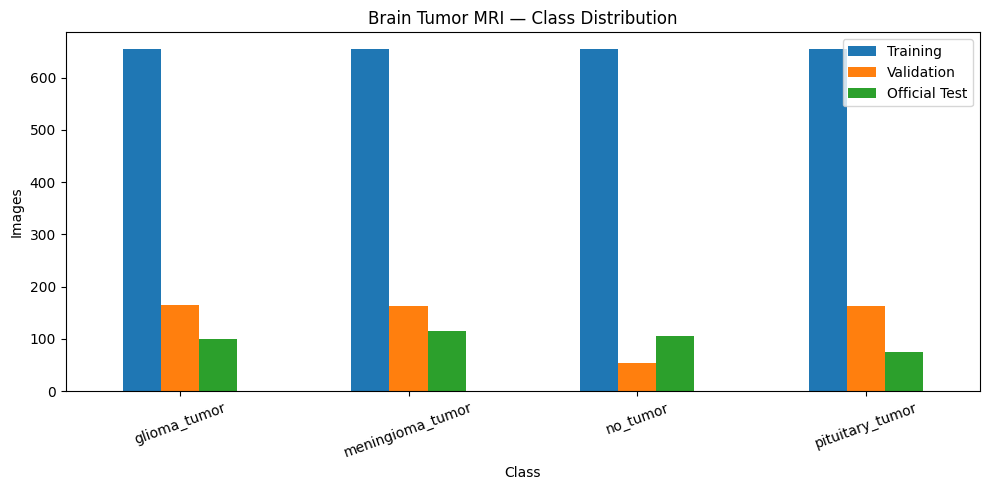

In [ ]:
IMAGE_EXTS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff"
}

CLASS_NAMES = sorted([
    p.name
    for p in TRAIN_DIR.iterdir()
    if p.is_dir()
])

NUM_CLASSES = len(
    CLASS_NAMES
)

assert NUM_CLASSES == 4

print("Exact class order:")
for i, class_name in enumerate(
    CLASS_NAMES
):
    print(
        i,
        "->",
        class_name
    )


def count_split(
    root
):
    rows = []

    for class_name in CLASS_NAMES:
        count = sum(
            1
            for p in (
                root / class_name
            ).rglob("*")
            if p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTS
        )

        rows.append({
            "Class": class_name,
            "Count": count
        })

    return pd.DataFrame(
        rows
    )


counts_df = (
    count_split(
        TRAIN_DIR
    ).rename(
        columns={
            "Count": "Training"
        }
    )
    .merge(
        count_split(
            VAL_DIR
        ).rename(
            columns={
                "Count": "Validation"
            }
        ),
        on="Class"
    )
    .merge(
        count_split(
            TEST_DIR
        ).rename(
            columns={
                "Count": "Official Test"
            }
        ),
        on="Class"
    )
)

display(
    counts_df
)

counts_df.set_index(
    "Class"
).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title(
    "Brain Tumor MRI — Class Distribution"
)

plt.ylabel(
    "Images"
)

plt.xticks(
    rotation=20
)

plt.tight_layout()
plt.show()

## 8. Build TensorFlow Datasets and Verify Exact Class Order

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=(
        IMG_SIZE,
        IMG_SIZE
    ),
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    VAL_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=(
        IMG_SIZE,
        IMG_SIZE
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=CLASS_NAMES,
    image_size=(
        IMG_SIZE,
        IMG_SIZE
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

train_ds = train_ds.prefetch(
    AUTOTUNE
)

val_ds = val_ds.prefetch(
    AUTOTUNE
)

test_ds = test_ds.prefetch(
    AUTOTUNE
)

images, labels = next(
    iter(
        train_ds
    )
)

print(
    "Image shape:",
    images.shape
)

print(
    "Input pixel range:",
    float(
        tf.reduce_min(
            images
        )
    ),
    "to",
    float(
        tf.reduce_max(
            images
        )
    )
)

Found 2616 files belonging to 4 classes.
Found 543 files belonging to 4 classes.
Found 394 files belonging to 4 classes.
Image shape: (32, 224, 224, 3)
Input pixel range: 0.0 to 255.0


## 9. Model-Specific Preprocessing and Training-Only Augmentation

The final Kaggle dataset has already completed the group's common image preprocessing.

Inside this notebook:
- Validation/Test are not augmented.
- Training receives mild or moderate augmentation depending on the variant.
- EfficientNetB0 includes its required input rescaling inside the Keras application model.

The saved `.keras` model therefore keeps its architecture-specific preprocessing consistent with deployment.

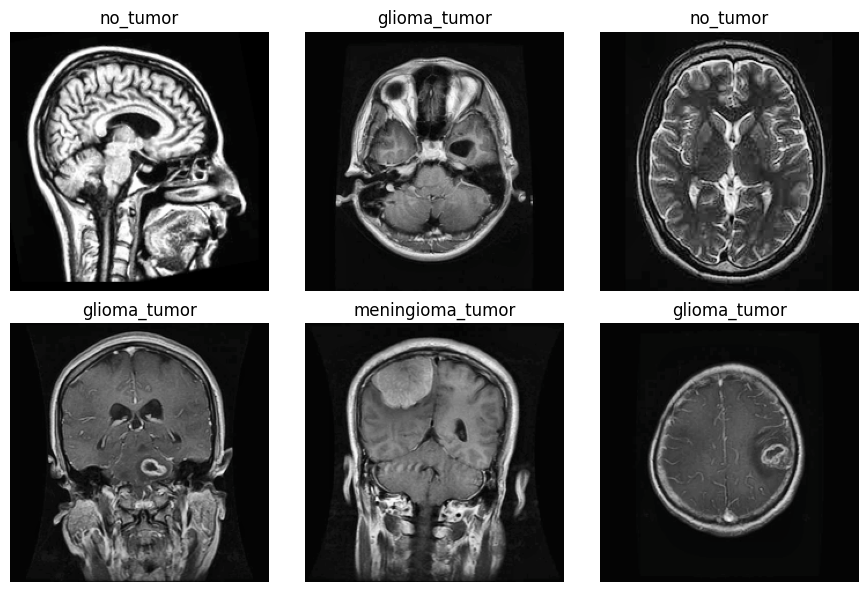

In [ ]:
plt.figure(
    figsize=(9, 6)
)

for i in range(
    min(
        6,
        images.shape[
            0
        ]
    )
):
    plt.subplot(
        2,
        3,
        i + 1
    )

    plt.imshow(
        tf.cast(
            images[
                i
            ],
            tf.uint8
        )
    )

    class_index = int(
        tf.argmax(
            labels[
                i
            ]
        )
    )

    plt.title(
        CLASS_NAMES[
            class_index
        ]
    )

    plt.axis(
        "off"
    )

plt.tight_layout()
plt.show()

## 10. Evaluation Metrics and Helper Functions

In [ ]:
def macro_f1():
    return tf.keras.metrics.F1Score(
        average="macro",
        name="f1_macro"
    )


def make_callbacks(
    checkpoint_path,
    patience
):
    return [
        keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            monitor="val_f1_macro",
            mode="max",
            save_best_only=True,
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor="val_f1_macro",
            mode="max",
            patience=patience,
            restore_best_weights=True,
            verbose=1
        ),

        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            mode="min",
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        ),
    ]


def compile_model(
    model,
    learning_rate,
    weight_decay
):
    model.compile(
        optimizer=keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=weight_decay
        ),
        loss=keras.losses.CategoricalCrossentropy(
            label_smoothing=0.05
        ),
        metrics=[
            keras.metrics.CategoricalAccuracy(
                name="accuracy"
            ),
            macro_f1()
        ]
    )


def get_predictions(
    model,
    dataset
):
    y_true = []
    probabilities = []

    for x_batch, y_batch in dataset:
        p = model.predict(
            x_batch,
            verbose=0
        )

        y_true.extend(
            np.argmax(
                y_batch.numpy(),
                axis=1
            )
        )

        probabilities.extend(
            p
        )

    return (
        np.asarray(
            y_true,
            dtype=np.int64
        ),
        np.asarray(
            probabilities,
            dtype=np.float32
        )
    )


def calculate_metrics(
    y_true,
    probabilities
):
    y_pred = np.argmax(
        probabilities,
        axis=1
    )

    return {
        "Accuracy": float(
            accuracy_score(
                y_true,
                y_pred
            )
        ),
        "Precision": float(
            precision_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "Recall": float(
            recall_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
        "F1": float(
            f1_score(
                y_true,
                y_pred,
                average="macro",
                zero_division=0
            )
        ),
    }


def evaluate_checkpoint(
    checkpoint_path,
    dataset
):
    model = keras.models.load_model(
        checkpoint_path,
        compile=False
    )

    y_true, probabilities = get_predictions(
        model,
        dataset
    )

    metrics = calculate_metrics(
        y_true,
        probabilities
    )

    return (
        model,
        y_true,
        probabilities,
        metrics
    )


def plot_history(
    history_df,
    title_prefix
):
    epochs = np.arange(
        1,
        len(
            history_df
        ) + 1
    )

    plt.figure(
        figsize=(8, 4)
    )
    plt.plot(
        epochs,
        history_df[
            "accuracy"
        ],
        label="Training Accuracy"
    )
    plt.plot(
        epochs,
        history_df[
            "val_accuracy"
        ],
        label="Validation Accuracy"
    )
    plt.title(
        f"{title_prefix} — Accuracy"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(
        figsize=(8, 4)
    )
    plt.plot(
        epochs,
        history_df[
            "loss"
        ],
        label="Training Loss"
    )
    plt.plot(
        epochs,
        history_df[
            "val_loss"
        ],
        label="Validation Loss"
    )
    plt.title(
        f"{title_prefix} — Loss"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()

    plt.figure(
        figsize=(8, 4)
    )
    plt.plot(
        epochs,
        history_df[
            "f1_macro"
        ],
        label="Training Macro F1"
    )
    plt.plot(
        epochs,
        history_df[
            "val_f1_macro"
        ],
        label="Validation Macro F1"
    )
    plt.title(
        f"{title_prefix} — Macro F1"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Macro F1")
    plt.legend()
    plt.tight_layout()
    plt.show()

## 11. Manual Hyperparameter Tuning Plan — Variant A vs Variant B

### Variant A — Strong Transfer Learning
- Dense head: 256
- Dropout: 0.35
- Head LR: 3e-4
- Fine-tune LR: 1e-5
- Fine-tune upper 40 backbone layers
- Light augmentation

### Variant B — Deep Fine-Tuning
- Dense head: 512 → 128
- Batch Normalization
- L2 regularization
- Dropout: 0.45
- Head LR: 1e-4
- Fine-tune LR: 5e-6
- Fine-tune upper 80 backbone layers
- Moderate augmentation

The selected variant is the one with the highest **Validation Macro F1**.

## 12. Build the Two ImageNet Model Variants

In [ ]:
MODEL_NAME = "EfficientNetB0"

VARIANT_NAMES = {
    "A": "Strong Transfer Learning",
    "B": "Deep Fine-Tuning",
}

VARIANTS = {
    "A": {
        "dense_units": 256,
        "second_dense": 0,
        "dropout": 0.35,
        "head_lr": 3e-4,
        "finetune_lr": 1e-5,
        "finetune_layers": 40,
        "weight_decay": 1e-5,
        "l2": 0.0,
        "stage1_epochs": 15,
        "stage2_epochs": 30,
        "augmentation": "light",
    },
    "B": {
        "dense_units": 512,
        "second_dense": 128,
        "dropout": 0.45,
        "head_lr": 1e-4,
        "finetune_lr": 5e-6,
        "finetune_layers": 80,
        "weight_decay": 2e-5,
        "l2": 1e-4,
        "stage1_epochs": 18,
        "stage2_epochs": 35,
        "augmentation": "moderate",
    },
}


def make_augmentation(
    strength
):
    if strength == "light":
        return keras.Sequential(
            [
                layers.RandomFlip(
                    "horizontal"
                ),
                layers.RandomRotation(
                    0.025
                ),
                layers.RandomTranslation(
                    0.025,
                    0.025
                ),
                layers.RandomZoom(
                    0.035
                ),
                layers.RandomContrast(
                    0.05
                ),
            ],
            name="light_augmentation"
        )

    return keras.Sequential(
        [
            layers.RandomFlip(
                "horizontal"
            ),
            layers.RandomRotation(
                0.04
            ),
            layers.RandomTranslation(
                0.04,
                0.04
            ),
            layers.RandomZoom(
                0.05
            ),
            layers.RandomContrast(
                0.08
            ),
        ],
        name="moderate_augmentation"
    )


def build_model(
    variant_name
):
    cfg = VARIANTS[
        variant_name
    ]

    inputs = keras.Input(
        shape=(
            IMG_SIZE,
            IMG_SIZE,
            3
        ),
        name="mri_image"
    )

    x = make_augmentation(
        cfg[
            "augmentation"
        ]
    )(inputs)

    backbone = tf.keras.applications.EfficientNetB0(
        input_shape=(
            IMG_SIZE,
            IMG_SIZE,
            3
        ),
        include_top=False,
        weights="imagenet",
        pooling="avg"
    )

    backbone.trainable = False

    x = backbone(
        x,
        training=False
    )

    if variant_name == "B":
        x = layers.BatchNormalization(
            name="head_batch_norm"
        )(x)

    x = layers.Dense(
        cfg[
            "dense_units"
        ],
        activation="swish",
        kernel_regularizer=regularizers.l2(
            cfg[
                "l2"
            ]
        ),
        name="head_dense_1"
    )(x)

    x = layers.Dropout(
        cfg[
            "dropout"
        ],
        name="head_dropout_1"
    )(x)

    if cfg[
        "second_dense"
    ] > 0:
        x = layers.Dense(
            cfg[
                "second_dense"
            ],
            activation="swish",
            kernel_regularizer=regularizers.l2(
                cfg[
                    "l2"
                ]
            ),
            name="head_dense_2"
        )(x)

        x = layers.Dropout(
            0.25,
            name="head_dropout_2"
        )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        dtype="float32",
        name="tumor_class"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name=(
            f"{MODEL_NAME}_"
            f"Variant_{variant_name}"
        )
    )

    return (
        model,
        backbone
    )


def set_finetune_layers(
    backbone,
    last_n
):
    backbone.trainable = True

    for layer in backbone.layers:
        layer.trainable = False

    for layer in backbone.layers[
        -last_n:
    ]:
        if not isinstance(
            layer,
            layers.BatchNormalization
        ):
            layer.trainable = True

    print(
        "Trainable backbone layers:",
        sum(
            int(
                layer.trainable
            )
            for layer in backbone.layers
        )
    )


def train_variant(
    variant_name
):
    cfg = VARIANTS[
        variant_name
    ]

    print(
        "TRAINING",
        MODEL_NAME,
        "VARIANT",
        variant_name,
        "—",
        VARIANT_NAMES[
            variant_name
        ]
    )

    model, backbone = build_model(
        variant_name
    )

    compile_model(
        model,
        cfg[
            "head_lr"
        ],
        cfg[
            "weight_decay"
        ]
    )

    stage1_path = (
        MODEL_DIR
        / (
            f"{MODEL_NAME}_"
            f"{variant_name}_"
            "stage1_best.keras"
        )
    )

    history1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=cfg[
            "stage1_epochs"
        ],
        callbacks=make_callbacks(
            stage1_path,
            patience=6
        ),
        verbose=1
    )

    _, _, _, stage1_metrics = evaluate_checkpoint(
        stage1_path,
        val_ds
    )

    model = keras.models.load_model(
        stage1_path,
        compile=False
    )

    backbone = None

    for layer in model.layers:
        if isinstance(
            layer,
            keras.Model
        ):
            backbone = layer

    assert backbone is not None

    set_finetune_layers(
        backbone,
        cfg[
            "finetune_layers"
        ]
    )

    compile_model(
        model,
        cfg[
            "finetune_lr"
        ],
        cfg[
            "weight_decay"
        ]
    )

    stage2_path = (
        MODEL_DIR
        / (
            f"{MODEL_NAME}_"
            f"{variant_name}_"
            "stage2_best.keras"
        )
    )

    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=cfg[
            "stage2_epochs"
        ],
        callbacks=make_callbacks(
            stage2_path,
            patience=8
        ),
        verbose=1
    )

    _, _, _, stage2_metrics = evaluate_checkpoint(
        stage2_path,
        val_ds
    )

    stage_results = pd.DataFrame(
        [
            {
                "Stage": "Frozen Backbone",
                **stage1_metrics
            },
            {
                "Stage": "Fine-Tuning",
                **stage2_metrics
            },
        ]
    ).sort_values(
        "F1",
        ascending=False
    ).reset_index(
        drop=True
    )

    if stage_results.loc[
        0,
        "Stage"
    ] == "Frozen Backbone":
        best_path = stage1_path
    else:
        best_path = stage2_path

    result = {
        "Variant": variant_name,
        "Variant Name": VARIANT_NAMES[
            variant_name
        ],
        "Best Stage": str(
            stage_results.loc[
                0,
                "Stage"
            ]
        ),
        "Validation Accuracy": float(
            stage_results.loc[
                0,
                "Accuracy"
            ]
        ),
        "Validation Precision": float(
            stage_results.loc[
                0,
                "Precision"
            ]
        ),
        "Validation Recall": float(
            stage_results.loc[
                0,
                "Recall"
            ]
        ),
        "Validation F1": float(
            stage_results.loc[
                0,
                "F1"
            ]
        ),
        "Best Checkpoint": str(
            best_path
        ),
    }

    return {
        "result": result,
        "history_stage1": pd.DataFrame(
            history1.history
        ),
        "history_stage2": pd.DataFrame(
            history2.history
        ),
        "stage_results": stage_results,
        "best_path": best_path,
    }

## 13. Train Variant A Separately — Strong Transfer Learning

In [ ]:
VARIANT_A = train_variant(
    "A"
)

display(
    pd.DataFrame([
        VARIANT_A[
            "result"
        ]
    ])
)

TRAINING EfficientNetB0 VARIANT A — Strong Transfer Learning
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - accuracy: 0.5760 - f1_macro: 0.5661 - loss: 1.0635
Epoch 1: val_f1_macro improved from None to 0.69871, saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_A_stage1_best.keras

Epoch 1: finished saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_A_stage1_best.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 33s 164ms/step - accuracy: 0.7034 - f1_macro: 0.6990 - loss: 0.8609 - val_accuracy: 0.6998 - val_f1_macro: 0.6987 - val_loss: 0.7894 - learning_rate: 3.0000e-04
Epoch 2/15
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.7976 - f1_macro: 0.7928 - loss: 0.6371
Epoch 2: val_f1_macro improved from 0.69871 to 0.74874, saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_A_stage1_best.keras

Epoch 2: finished saving model to /content/brain_tumor_high_performance/mod

,Variant,Variant Name,Best Stage,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Best Checkpoint
0,A,Strong Transfer Learning,Fine-Tuning,0.848987,0.869536,0.846576,0.853173,/content/brain_tumor_high_performance/models/E...


## 14. Variant A Visualization — Accuracy, Loss and Macro F1

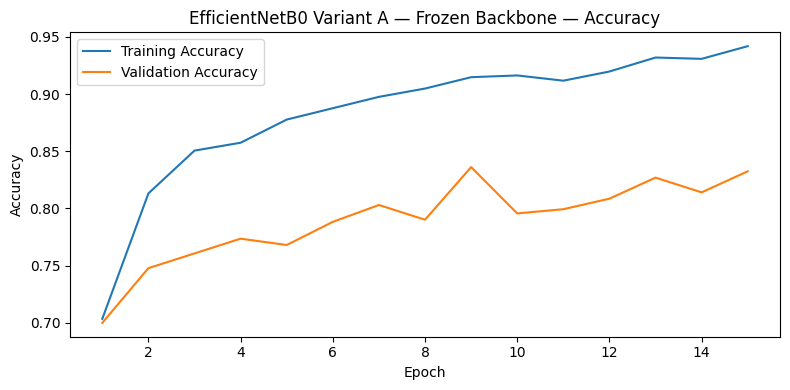

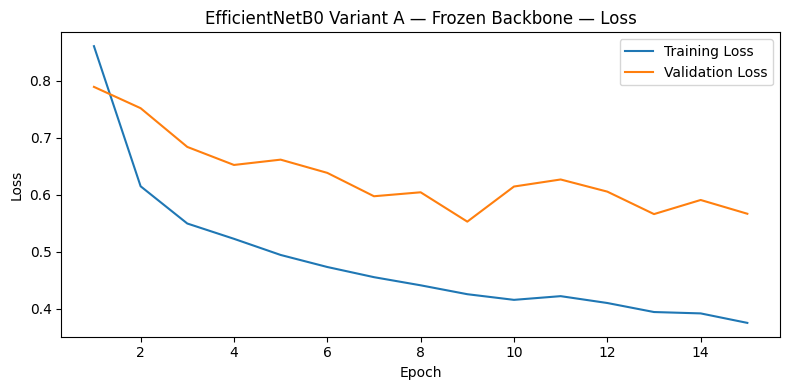

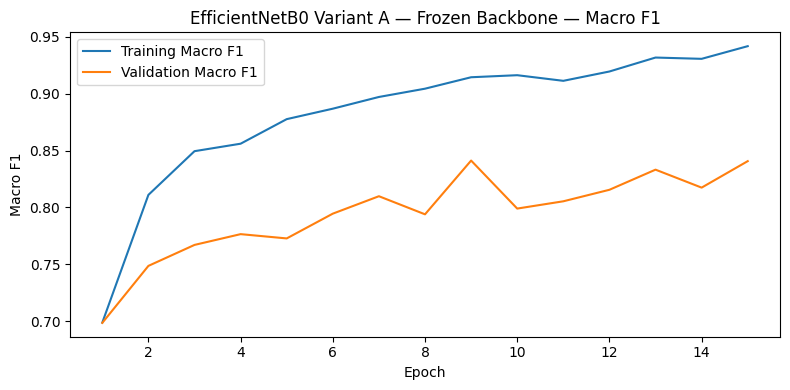

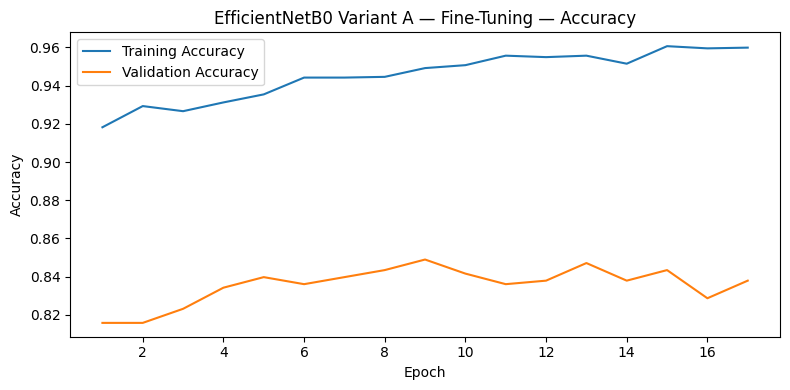

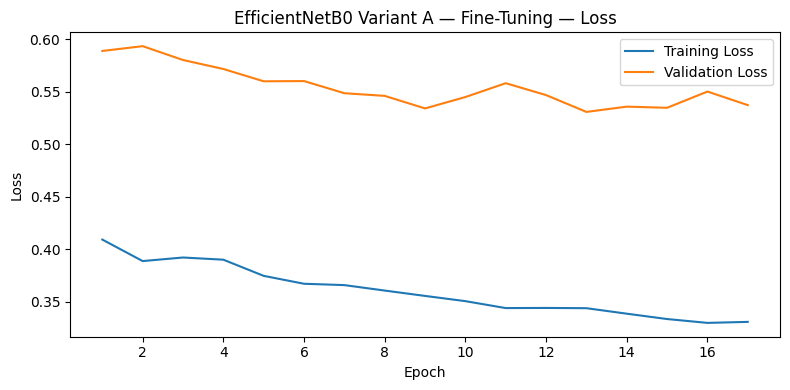

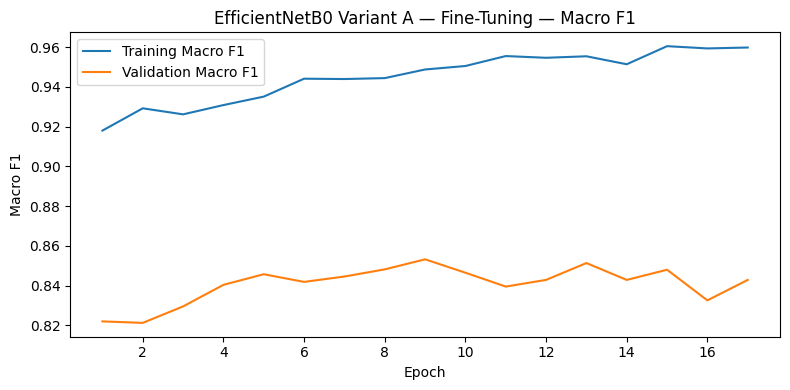

,Stage,Accuracy,Precision,Recall,F1
0,Fine-Tuning,0.848987,0.869536,0.846576,0.853173
1,Frozen Backbone,0.836096,0.853285,0.835914,0.841173


In [ ]:
plot_history(
    VARIANT_A[
        "history_stage1"
    ],
    (
        f"{MODEL_NAME} Variant A — "
        "Frozen Backbone"
    )
)

plot_history(
    VARIANT_A[
        "history_stage2"
    ],
    (
        f"{MODEL_NAME} Variant A — "
        "Fine-Tuning"
    )
)

display(
    VARIANT_A[
        "stage_results"
    ]
)

## 15. Train Variant B Separately — Deep Fine-Tuning

In [ ]:
VARIANT_B = train_variant(
    "B"
)

display(
    pd.DataFrame([
        VARIANT_B[
            "result"
        ]
    ])
)

TRAINING EfficientNetB0 VARIANT B — Deep Fine-Tuning
Epoch 1/18
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.4569 - f1_macro: 0.4520 - loss: 1.4315
Epoch 1: val_f1_macro improved from None to 0.65422, saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_B_stage1_best.keras

Epoch 1: finished saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_B_stage1_best.keras
82/82 ━━━━━━━━━━━━━━━━━━━━ 24s 150ms/step - accuracy: 0.5669 - f1_macro: 0.5630 - loss: 1.2128 - val_accuracy: 0.6575 - val_f1_macro: 0.6542 - val_loss: 1.0425 - learning_rate: 1.0000e-04
Epoch 2/18
82/82 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7291 - f1_macro: 0.7226 - loss: 0.9149
Epoch 2: val_f1_macro improved from 0.65422 to 0.69742, saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_B_stage1_best.keras

Epoch 2: finished saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_B_stage1_best.keras
82/82 ━━━━━━━━━━━━━━

,Variant,Variant Name,Best Stage,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Best Checkpoint
0,B,Deep Fine-Tuning,Fine-Tuning,0.839779,0.868238,0.851225,0.848362,/content/brain_tumor_high_performance/models/E...


## 16. Variant B Visualization — Accuracy, Loss and Macro F1

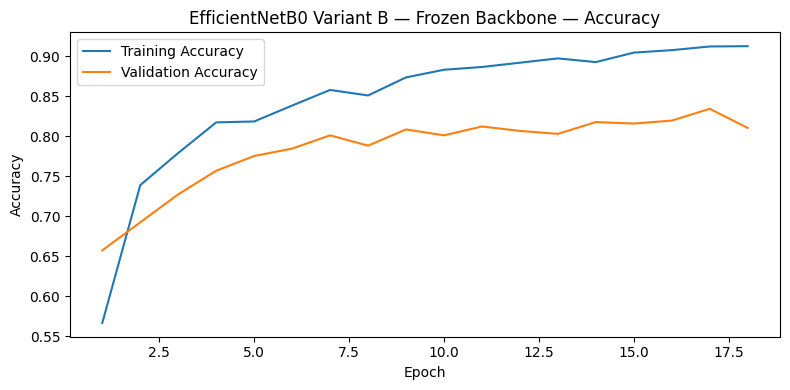

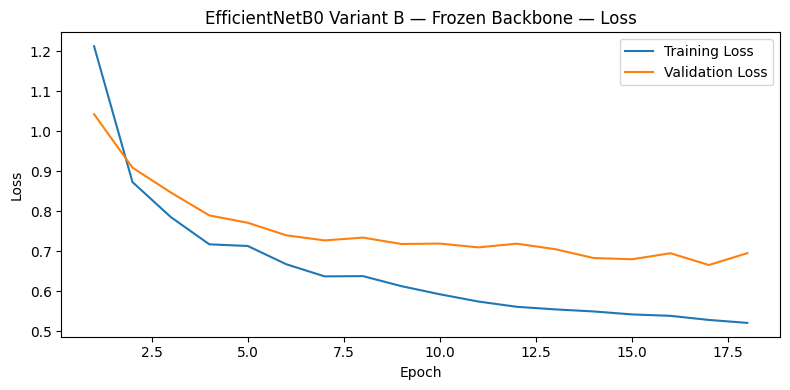

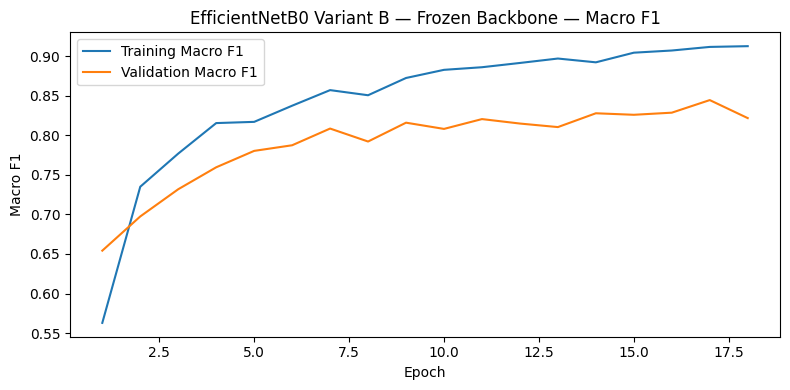

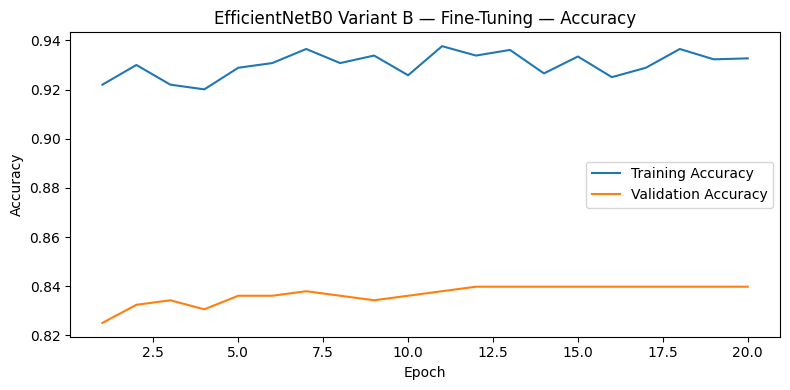

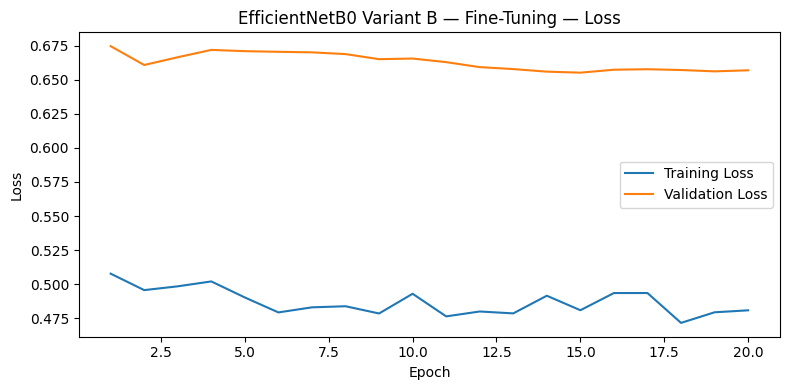

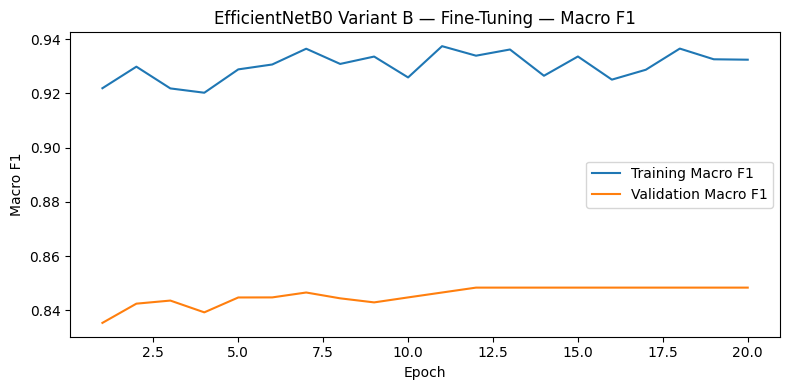

,Stage,Accuracy,Precision,Recall,F1
0,Fine-Tuning,0.839779,0.868238,0.851225,0.848362
1,Frozen Backbone,0.834254,0.860657,0.846624,0.844347


In [ ]:
plot_history(
    VARIANT_B[
        "history_stage1"
    ],
    (
        f"{MODEL_NAME} Variant B — "
        "Frozen Backbone"
    )
)

plot_history(
    VARIANT_B[
        "history_stage2"
    ],
    (
        f"{MODEL_NAME} Variant B — "
        "Fine-Tuning"
    )
)

display(
    VARIANT_B[
        "stage_results"
    ]
)

## 17. Compare Variant A vs Variant B and Select the Best

,Variant,Variant Name,Best Stage,Validation Accuracy,Validation Precision,Validation Recall,Validation F1,Best Checkpoint
0,A,Strong Transfer Learning,Fine-Tuning,0.848987,0.869536,0.846576,0.853173,/content/brain_tumor_high_performance/models/E...
1,B,Deep Fine-Tuning,Fine-Tuning,0.839779,0.868238,0.851225,0.848362,/content/brain_tumor_high_performance/models/E...


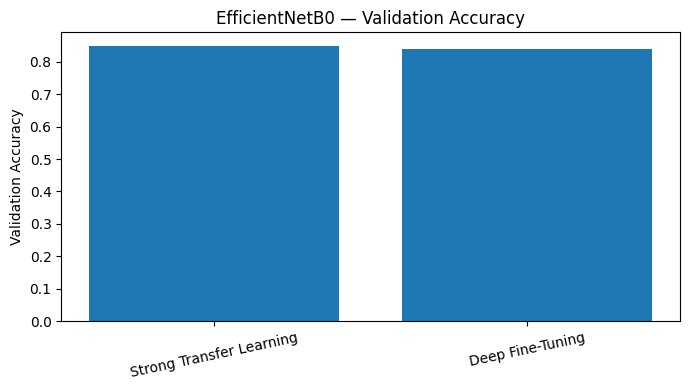

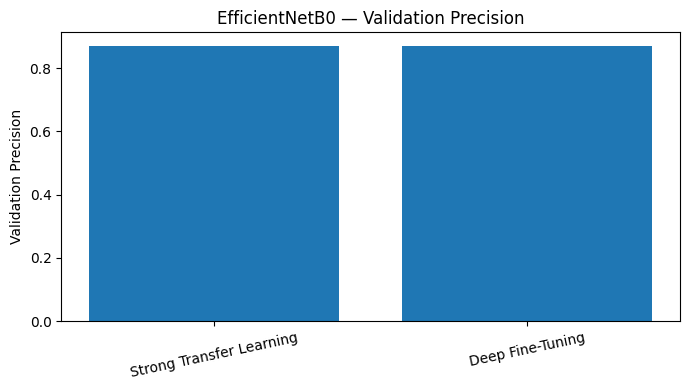

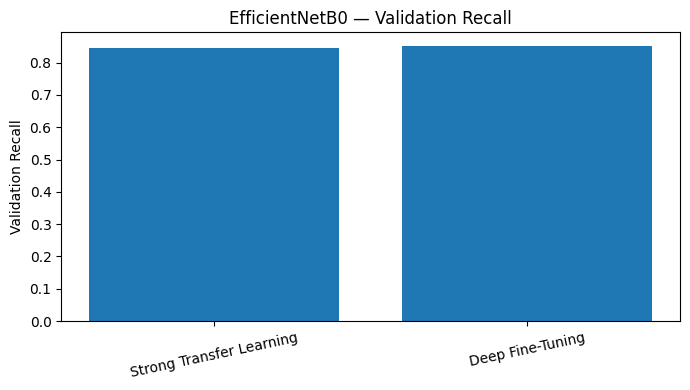

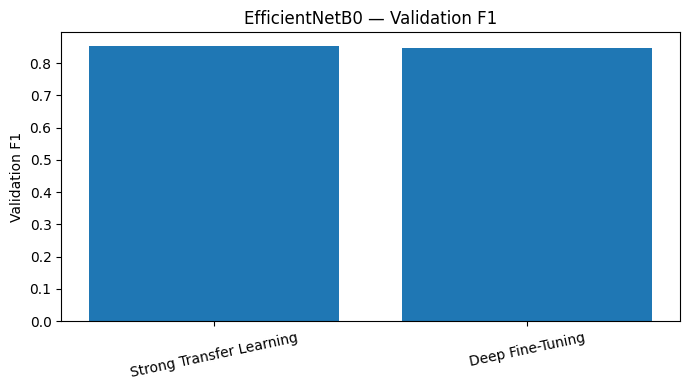

Selected: A — Strong Transfer Learning
Selection metric: Validation Macro F1


In [ ]:
variant_results = pd.DataFrame([
    VARIANT_A[
        "result"
    ],
    VARIANT_B[
        "result"
    ],
]).sort_values(
    "Validation F1",
    ascending=False
).reset_index(
    drop=True
)

display(
    variant_results
)

for metric in [
    "Validation Accuracy",
    "Validation Precision",
    "Validation Recall",
    "Validation F1"
]:
    plt.figure(
        figsize=(7, 4)
    )

    plt.bar(
        variant_results[
            "Variant Name"
        ],
        variant_results[
            metric
        ]
    )

    plt.title(
        f"{MODEL_NAME} — {metric}"
    )

    plt.ylabel(
        metric
    )

    plt.xticks(
        rotation=12
    )

    plt.tight_layout()
    plt.show()

BEST_VARIANT = str(
    variant_results.loc[
        0,
        "Variant"
    ]
)

BEST_VARIANT_NAME = str(
    variant_results.loc[
        0,
        "Variant Name"
    ]
)

BEST_CHECKPOINT = Path(
    variant_results.loc[
        0,
        "Best Checkpoint"
    ]
)

FINAL_MODEL_PATH = (
    MODEL_DIR
    / (
        f"{MODEL_NAME}_"
        "BEST_BRAIN_TUMOR_MODEL.keras"
    )
)

shutil.copy2(
    BEST_CHECKPOINT,
    FINAL_MODEL_PATH
)

print(
    "Selected:",
    BEST_VARIANT,
    "—",
    BEST_VARIANT_NAME
)

print(
    "Selection metric:",
    "Validation Macro F1"
)

## 18. 5-Fold Stratified Cross-Validation — Selected Variant

The selected Variant A/B configuration is evaluated using **5-fold stratified cross-validation on the Training split only**. The model is rebuilt and retrained independently in every fold. The normal held-out Validation set and the Official Test set are not included in these folds.

The output includes Fold 1–5 Accuracy, Macro Precision, Macro Recall and **Macro F1**, plus the Mean CV Macro F1 and standard deviation. The owner-specific summary is exported as `*_5fold_cv_summary.csv` for the final six-model comparison.

> **Report screenshot:** capture the 5-fold summary table and Macro F1 chart after this cell finishes.


5-fold CV samples: 2616
Class counts: {'glioma_tumor': 654, 'meningioma_tumor': 654, 'no_tumor': 654, 'pituitary_tumor': 654}

5-FOLD CV — FOLD 1/5
Selected variant: A — Strong Transfer Learning
TRAINING EfficientNetB0 VARIANT A — Strong Transfer Learning
Epoch 1/15
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.5529 - f1_macro: 0.5425 - loss: 1.0742
Epoch 1: val_f1_macro improved from None to 0.73178, saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_A_stage1_best.keras

Epoch 1: finished saving model to /content/brain_tumor_high_performance/models/EfficientNetB0_A_stage1_best.keras
66/66 ━━━━━━━━━━━━━━━━━━━━ 22s 182ms/step - accuracy: 0.6730 - f1_macro: 0.6681 - loss: 0.8871 - val_accuracy: 0.7481 - val_f1_macro: 0.7318 - val_loss: 0.7327 - learning_rate: 3.0000e-04
Epoch 2/15
65/66 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.7953 - f1_macro: 0.7837 - loss: 0.6388
Epoch 2: val_f1_macro did not improve from 0.73178
66/66 ━━━━━━━━━━━━━━━━━━━━ 7s 109

,Fold,Accuracy,Macro Precision,Macro Recall,Macro F1
0,1,0.883588,0.889894,0.883588,0.883687
1,2,0.873805,0.881113,0.874031,0.870672
2,3,0.908222,0.910227,0.908368,0.905774
3,4,0.929254,0.928934,0.929008,0.927608
4,5,0.887189,0.889807,0.887140,0.886809



5-FOLD CROSS-VALIDATION SUMMARY


,Member,Owner,IT Number,Model,Selected Variant,Selected Variant Name,Fold 1 F1,Fold 2 F1,Fold 3 F1,Fold 4 F1,Fold 5 F1,Mean CV F1,Std CV F1
0,2,Hettiarachchi H.A.A.S,IT25104064,EfficientNetB0,A,Strong Transfer Learning,0.883687,0.870672,0.905774,0.927608,0.886809,0.89491,0.022171


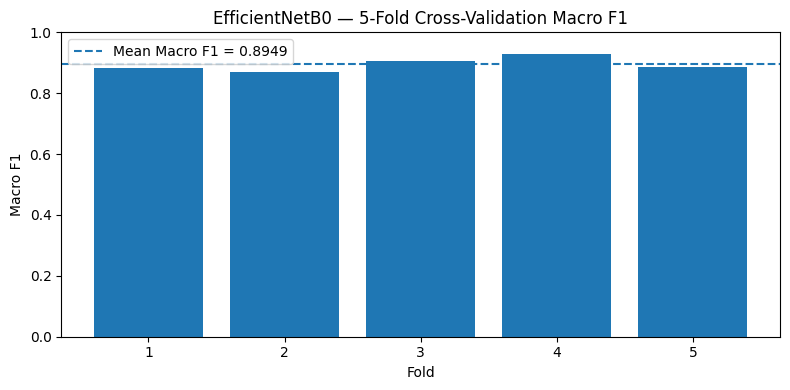

Saved fold results: /content/brain_tumor_high_performance/results/it25104064_efficientnetb0_5fold_cv_folds.csv
Saved CV summary: /content/brain_tumor_high_performance/results/it25104064_efficientnetb0_5fold_cv_summary.csv


In [ ]:

# 5-FOLD STRATIFIED CROSS-VALIDATION — SELECTED VARIANT ONLY
# IMPORTANT:
# - Uses the Training split only.
# - Official Validation and Official Test remain untouched.
# - The selected A/B configuration is rebuilt and retrained
#   separately in every fold.

from sklearn.model_selection import StratifiedKFold

CV_N_SPLITS = 5

# Collect Training image paths and integer class labels.
CV_IMAGE_EXTS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff"
}

cv_paths = []
cv_labels = []

for class_index, class_name in enumerate(CLASS_NAMES):
    class_dir = TRAIN_DIR / class_name

    class_paths = sorted([
        p
        for p in class_dir.rglob("*")
        if p.is_file() and p.suffix.lower() in CV_IMAGE_EXTS
    ])

    cv_paths.extend([
        str(p) for p in class_paths
    ])

    cv_labels.extend([
        class_index
    ] * len(class_paths))

cv_paths = np.asarray(cv_paths)
cv_labels = np.asarray(cv_labels, dtype=np.int64)

print("5-fold CV samples:", len(cv_paths))
print(
    "Class counts:",
    {
        CLASS_NAMES[i]: int(np.sum(cv_labels == i))
        for i in range(NUM_CLASSES)
    }
)

if isinstance(IMG_SIZE, (tuple, list)):
    CV_HEIGHT = int(IMG_SIZE[0])
    CV_WIDTH = int(IMG_SIZE[1])
else:
    CV_HEIGHT = int(IMG_SIZE)
    CV_WIDTH = int(IMG_SIZE)

def _cv_load_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.cast(
        image,
        tf.float32
    )

    image = tf.image.resize_with_pad(
        image,
        CV_HEIGHT,
        CV_WIDTH
    )

    label = tf.one_hot(
        label,
        depth=NUM_CLASSES
    )

    return image, label


def _make_cv_dataset(
    paths,
    labels,
    training
):
    ds = tf.data.Dataset.from_tensor_slices(
        (
            paths.astype(str),
            labels.astype(np.int64)
        )
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        _cv_load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE
    )

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds


skf = StratifiedKFold(
    n_splits=CV_N_SPLITS,
    shuffle=True,
    random_state=SEED
)

cv_rows = []

# Preserve the normal held-out Validation workflow.
_ORIGINAL_TRAIN_DS = train_ds
_ORIGINAL_VAL_DS = val_ds

for fold_no, (fold_train_idx, fold_val_idx) in enumerate(
    skf.split(cv_paths, cv_labels),
    start=1
):
    print(
        "\n"
        + "=" * 80
    )
    print(
        f"5-FOLD CV — FOLD {fold_no}/{CV_N_SPLITS}"
    )
    print(
        "Selected variant:",
        BEST_VARIANT,
        "—",
        BEST_VARIANT_NAME
    )
    print(
        "=" * 80
    )

    train_ds = _make_cv_dataset(
        cv_paths[fold_train_idx],
        cv_labels[fold_train_idx],
        training=True
    )

    val_ds = _make_cv_dataset(
        cv_paths[fold_val_idx],
        cv_labels[fold_val_idx],
        training=False
    )

    fold_pack = train_variant(
        BEST_VARIANT
    )

    fold_result = fold_pack[
        "result"
    ]

    cv_rows.append({
        "Fold": fold_no,
        "Accuracy": float(
            fold_result[
                "Validation Accuracy"
            ]
        ),
        "Macro Precision": float(
            fold_result[
                "Validation Precision"
            ]
        ),
        "Macro Recall": float(
            fold_result[
                "Validation Recall"
            ]
        ),
        "Macro F1": float(
            fold_result[
                "Validation F1"
            ]
        ),
    })

    tf.keras.backend.clear_session()
    gc.collect()

# Restore the original normal-validation datasets.
train_ds = _ORIGINAL_TRAIN_DS
val_ds = _ORIGINAL_VAL_DS

cv_df = pd.DataFrame(
    cv_rows
)

print(
    "\n5-FOLD CROSS-VALIDATION RESULTS"
)

display(
    cv_df
)

fold_f1 = cv_df[
    "Macro F1"
].to_numpy()

cv_summary = pd.DataFrame([
    {
        "Member": OWNER_MEMBER_NO,
        "Owner": MODEL_OWNER,
        "IT Number": OWNER_IT_NUMBER,
        "Model": MODEL_NAME,
        "Selected Variant": BEST_VARIANT,
        "Selected Variant Name": BEST_VARIANT_NAME,
        "Fold 1 F1": float(fold_f1[0]),
        "Fold 2 F1": float(fold_f1[1]),
        "Fold 3 F1": float(fold_f1[2]),
        "Fold 4 F1": float(fold_f1[3]),
        "Fold 5 F1": float(fold_f1[4]),
        "Mean CV F1": float(
            np.mean(
                fold_f1
            )
        ),
        "Std CV F1": float(
            np.std(
                fold_f1,
                ddof=1
            )
        ),
    }
])

print(
    "\n5-FOLD CROSS-VALIDATION SUMMARY"
)

display(
    cv_summary
)

plt.figure(
    figsize=(8, 4)
)

plt.bar(
    cv_df[
        "Fold"
    ].astype(str),
    cv_df[
        "Macro F1"
    ]
)

plt.axhline(
    cv_df[
        "Macro F1"
    ].mean(),
    linestyle="--",
    label=(
        "Mean Macro F1 = "
        f"{cv_df['Macro F1'].mean():.4f}"
    )
)

plt.title(
    f"{MODEL_NAME} — 5-Fold Cross-Validation Macro F1"
)

plt.xlabel("Fold")
plt.ylabel("Macro F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()

CV_FOLDS_CSV = (
    RESULTS_DIR
    / (
        f"{MODEL_NAME.lower()}_"
        "5fold_cv_folds.csv"
    )
)

CV_SUMMARY_CSV = (
    RESULTS_DIR
    / (
        f"{MODEL_NAME.lower()}_"
        "5fold_cv_summary.csv"
    )
)

cv_file_prefix = (
    OWNER_IT_NUMBER.lower()
    + "_"
    + MODEL_NAME.lower().replace(" ", "_")
)

CV_FOLDS_CSV = (
    RESULTS_DIR
    / f"{cv_file_prefix}_5fold_cv_folds.csv"
)

CV_SUMMARY_CSV = (
    RESULTS_DIR
    / f"{cv_file_prefix}_5fold_cv_summary.csv"
)

cv_df.to_csv(
    CV_FOLDS_CSV,
    index=False
)

cv_summary.to_csv(
    CV_SUMMARY_CSV,
    index=False
)

print(
    "Saved fold results:",
    CV_FOLDS_CSV
)

print(
    "Saved CV summary:",
    CV_SUMMARY_CSV
)

## 19. Official Test Evaluation, Error Analysis and Result Export

The Official Test set is used only **after** Variant A/B selection.

Outputs:
- selected `.keras` model,
- final result CSV,
- variant comparison CSV,
- classification report,
- confusion matrix,
- metadata JSON.

,Test Accuracy,Test Precision,Test Recall,Test F1
0,0.700508,0.715766,0.711718,0.690475


,precision,recall,f1-score,support
glioma_tumor,0.693878,0.340000,0.456376,100.000000
meningioma_tumor,0.612500,0.852174,0.712727,115.000000
no_tumor,0.784946,0.695238,0.737374,105.000000
pituitary_tumor,0.771739,0.959459,0.855422,74.000000
accuracy,0.700508,0.700508,0.700508,0.700508
macro avg,0.715766,0.711718,0.690475,394.000000
weighted avg,0.709019,0.700508,0.681032,394.000000


,Pred glioma_tumor,Pred meningioma_tumor,Pred no_tumor,Pred pituitary_tumor
True glioma_tumor,34,42,17,7
True meningioma_tumor,7,98,3,7
True no_tumor,8,17,73,7
True pituitary_tumor,0,3,0,71


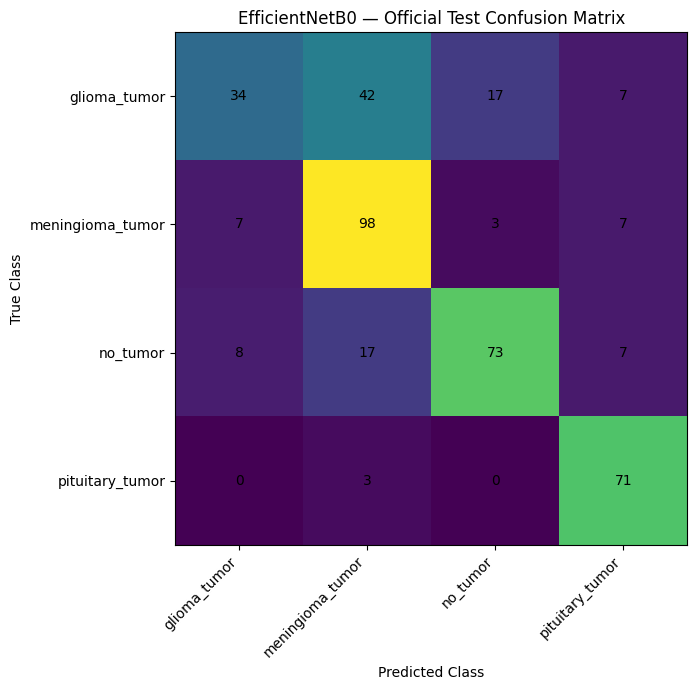

,Model Owner,IT Number,Model,Weights,Selected Variant,Selected Variant Name,Validation F1,Test Accuracy,Test Precision,Test Recall,Test F1
0,Hettiarachchi H.A.A.S,IT25104064,EfficientNetB0,ImageNet,A,Strong Transfer Learning,0.853173,0.700508,0.715766,0.711718,0.690475


Saved final model: /content/brain_tumor_high_performance/models/EfficientNetB0_BEST_BRAIN_TUMOR_MODEL.keras


In [ ]:
final_model = keras.models.load_model(
    FINAL_MODEL_PATH,
    compile=False
)

y_test_true, test_probs = get_predictions(
    final_model,
    test_ds
)

test_metrics = calculate_metrics(
    y_test_true,
    test_probs
)

TEST_METRICS = {
    "Test Accuracy": test_metrics[
        "Accuracy"
    ],
    "Test Precision": test_metrics[
        "Precision"
    ],
    "Test Recall": test_metrics[
        "Recall"
    ],
    "Test F1": test_metrics[
        "F1"
    ],
}

display(
    pd.DataFrame([
        TEST_METRICS
    ])
)

test_pred = np.argmax(
    test_probs,
    axis=1
)

report_dict = classification_report(
    y_test_true,
    test_pred,
    target_names=CLASS_NAMES,
    zero_division=0,
    output_dict=True
)

report_df = pd.DataFrame(
    report_dict
).transpose()

display(
    report_df
)

cm = confusion_matrix(
    y_test_true,
    test_pred
)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"True {x}"
        for x in CLASS_NAMES
    ],
    columns=[
        f"Pred {x}"
        for x in CLASS_NAMES
    ]
)

display(
    cm_df
)

plt.figure(
    figsize=(8, 7)
)

plt.imshow(
    cm
)

plt.title(
    f"{MODEL_NAME} — Official Test Confusion Matrix"
)

plt.xlabel(
    "Predicted Class"
)

plt.ylabel(
    "True Class"
)

plt.xticks(
    np.arange(
        NUM_CLASSES
    ),
    CLASS_NAMES,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(
        NUM_CLASSES
    ),
    CLASS_NAMES
)

for i in range(
    cm.shape[
        0
    ]
):
    for j in range(
        cm.shape[
            1
        ]
    ):
        plt.text(
            j,
            i,
            str(
                cm[
                    i,
                    j
                ]
            ),
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

FINAL_RESULT_CSV = (
    RESULTS_DIR
    / (
        f"{MODEL_NAME.lower()}_"
        "final_result.csv"
    )
)

VARIANT_CSV = (
    RESULTS_DIR
    / (
        f"{MODEL_NAME.lower()}_"
        "variant_comparison.csv"
    )
)

REPORT_CSV = (
    RESULTS_DIR
    / (
        f"{MODEL_NAME.lower()}_"
        "classification_report.csv"
    )
)

CM_CSV = (
    RESULTS_DIR
    / (
        f"{MODEL_NAME.lower()}_"
        "confusion_matrix.csv"
    )
)

final_result = pd.DataFrame([
    {
        "Model Owner": MODEL_OWNER,
        "IT Number": OWNER_IT_NUMBER,
        "Model": MODEL_NAME,
        "Weights": "ImageNet",
        "Selected Variant": BEST_VARIANT,
        "Selected Variant Name": BEST_VARIANT_NAME,
        "Validation F1": float(
            variant_results.loc[
                0,
                "Validation F1"
            ]
        ),
        **TEST_METRICS,
    }
])

final_result.to_csv(
    FINAL_RESULT_CSV,
    index=False
)

variant_results.to_csv(
    VARIANT_CSV,
    index=False
)

report_df.to_csv(
    REPORT_CSV
)

cm_df.to_csv(
    CM_CSV
)

metadata = {
    "model_owner": MODEL_OWNER,
    "owner_it_number": OWNER_IT_NUMBER,
    "owner_member_no": OWNER_MEMBER_NO,
    "model_name": MODEL_NAME,
    "weights": "ImageNet",
    "selected_variant": BEST_VARIANT,
    "selected_variant_name": BEST_VARIANT_NAME,
    "selection_metric": "Validation Macro F1",
    "validation_f1_macro": float(
        variant_results.loc[
            0,
            "Validation F1"
        ]
    ),
    "test_metrics": TEST_METRICS,
    "class_names": CLASS_NAMES,
    "input_size": [
        IMG_SIZE,
        IMG_SIZE
    ],
    "model_input_range": "0-255 float32",
    "dataset": KAGGLE_DATASET,
    "variant_configs": VARIANTS,
}

METADATA_PATH = (
    RESULTS_DIR
    / "best_model_metadata.json"
)

with open(
    METADATA_PATH,
    "w"
) as f:
    json.dump(
        metadata,
        f,
        indent=2
    )

display(
    final_result
)

print(
    "Saved final model:",
    FINAL_MODEL_PATH
)

## 20. Download Final EfficientNetB0 Package

The final `.keras` model is downloaded in the last cell for later localhost deployment.

In [ ]:
from google.colab import files

PACKAGE_DIR = (
    WORK_DIR
    / (
        f"{MODEL_NAME}_"
        "FINAL_PACKAGE"
    )
)

if PACKAGE_DIR.exists():
    shutil.rmtree(
        PACKAGE_DIR
    )

PACKAGE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

for src in [
    FINAL_MODEL_PATH,
    FINAL_RESULT_CSV,
    VARIANT_CSV,
    REPORT_CSV,
    CM_CSV,
    METADATA_PATH,
]:
    shutil.copy2(
        src,
        PACKAGE_DIR
        / Path(
            src
        ).name
    )

PACKAGE_ZIP = Path(
    shutil.make_archive(
        f"/content/{MODEL_NAME}_FINAL_PACKAGE",
        "zip",
        root_dir=PACKAGE_DIR
    )
)

files.download(
    str(
        FINAL_MODEL_PATH
    )
)

files.download(
    str(
        FINAL_RESULT_CSV
    )
)

files.download(
    str(
        METADATA_PATH
    )
)

files.download(
    str(
        PACKAGE_ZIP
    )
)

# Download 5-fold cross-validation outputs.
if "CV_FOLDS_CSV" in globals():
    files.download(str(CV_FOLDS_CSV))

if "CV_SUMMARY_CSV" in globals():
    files.download(str(CV_SUMMARY_CSV))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>